In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path.cwd() / "results" / "features" / "dev.npz"

if not data_path.exists():
    data_path = Path.cwd().parent / "results" / "features" / "dev.npz"

data = np.load(data_path)

hist = data["hist"]
shape = data["shape"]
hue = data["hue"]
labels = data["label"]

print("Total images:", len(labels))
print("Histogram shape:", hist.shape)
print("Shape features:", shape.shape)
print("Hue fractions:", hue.shape)
print("Classes:", np.unique(labels))

Total images: 730
Histogram shape: (730, 64)
Shape features: (730, 3)
Hue fractions: (730, 4)
Classes: ['apple' 'banana' 'orange']


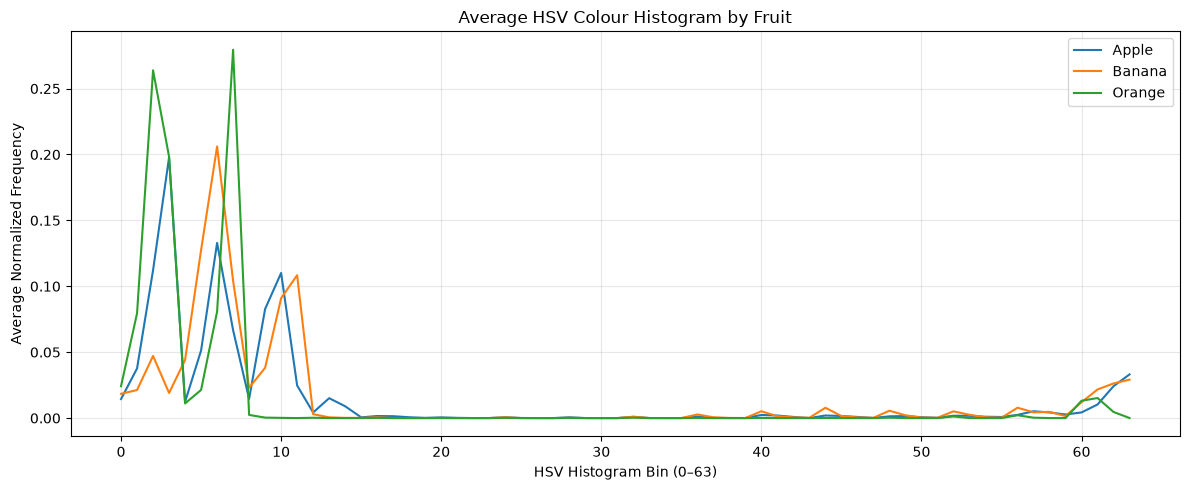

In [4]:
fruits = ["apple", "banana", "orange"]

plt.figure(figsize=(12, 5))

for fruit in fruits:
    mean_hist = hist[labels == fruit].mean(axis=0)
    plt.plot(mean_hist, label=fruit.capitalize())

plt.xlabel("HSV Histogram Bin (0–63)")
plt.ylabel("Average Normalized Frequency")
plt.title("Average HSV Colour Histogram by Fruit")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

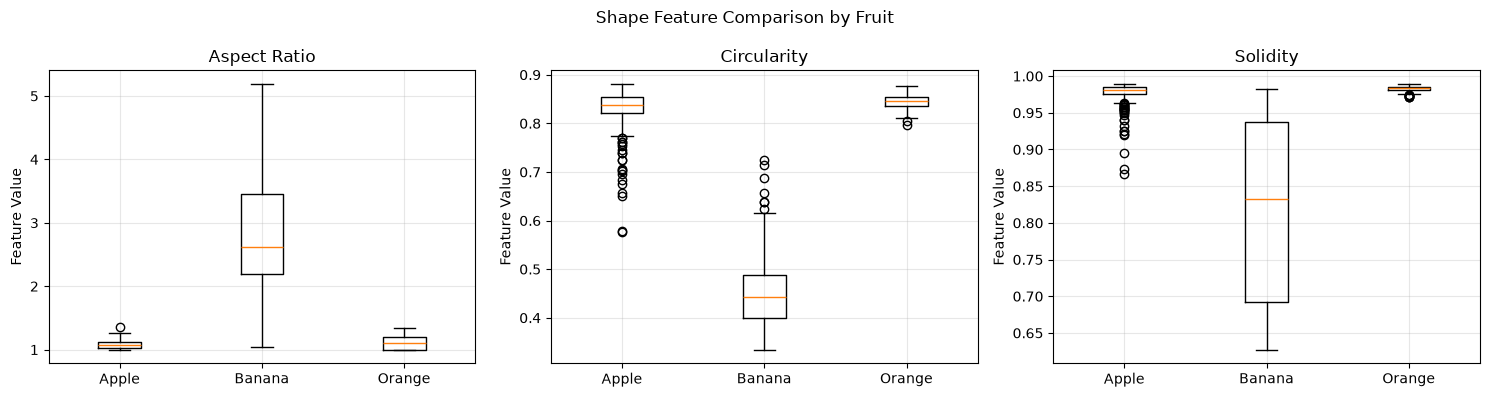

In [5]:
feature_names = ["Aspect Ratio", "Circularity", "Solidity"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, name in enumerate(feature_names):
    values = [shape[labels == fruit, i] for fruit in fruits]

    axes[i].boxplot(values, tick_labels=["Apple", "Banana", "Orange"])
    axes[i].set_title(name)
    axes[i].set_ylabel("Feature Value")
    axes[i].grid(alpha=0.3)

plt.suptitle("Shape Feature Comparison by Fruit")
plt.tight_layout()
plt.show()

In [6]:
print(f"{'Fruit':<10} {'Feature':<15} {'Mean':>10} {'Std Dev':>10}")
print("-" * 48)

for fruit in fruits:
    fruit_shape = shape[labels == fruit]

    for i, name in enumerate(feature_names):
        mean = fruit_shape[:, i].mean()
        std = fruit_shape[:, i].std()

        print(f"{fruit:<10} {name:<15} {mean:>10.4f} {std:>10.4f}")

Fruit      Feature               Mean    Std Dev
------------------------------------------------
apple      Aspect Ratio        1.0828     0.0664
apple      Circularity         0.8277     0.0463
apple      Solidity            0.9761     0.0163
banana     Aspect Ratio        2.8448     0.8864
banana     Circularity         0.4510     0.0670
banana     Solidity            0.8158     0.1181
orange     Aspect Ratio        1.1065     0.1019
orange     Circularity         0.8448     0.0147
orange     Solidity            0.9828     0.0034
